# Monalisa tutorial 1: from Siemens raw data to 3D images

Python counterpart of the MATLAB tutorial 1 (`demo/script_demo/script_tutorial_1/*.m` in
[monalisa](https://github.com/MattechLab/monalisa)), in four steps:

1. **Coil sensitivity estimation** from a body-coil and a surface-coil prescan.
2. **Binning**: choose which acquired lines go into each image (here: all lines, and 5 s windows).
3. **Mitosius**: normalize the raw data and split it into bins, saved to disk.
4. **Gridded reconstructions** (`bmMathilda`) of each bin.

The computations are the same as `tutorial_1.py` in this folder (the script version, used by the
end-to-end comparison with MATLAB). Differences from the MATLAB tutorial:

- no dialogs: the raw-data readers use `autoFlag=True`, and the metadata corrections the MATLAB
  dialogs ask for are set in code;
- the normalization region that MATLAB asks you to draw (`roipoly`) is a centered disk.

**Data.** Download it once (about 7.9 GB) with

```bash
python demo/data_demo/data_8_tutorial_1/download_data.py
```

or set `DATA` below to an existing copy (for instance the one of the MATLAB repository).
The full notebook takes about 10 minutes and 20 GB of memory.

In [1]:
import contextlib
import io
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import monalisa as ml
from monalisa.readWrite._mat73 import savemat73

DATA = Path(os.environ.get("MONALISA_TUTORIAL_DATA", "../../demo/data_demo/data_8_tutorial_1"))
OUT = Path("results")  # results of every step are saved here (.mat, readable with loadmat73)
OUT.mkdir(exist_ok=True)
for f in ("bodyCoil.dat", "surfaceCoil.dat", "brainScan.dat"):
    assert (DATA / f).exists(), f"{DATA / f} not found: run demo/data_demo/data_8_tutorial_1/download_data.py"


def quiet():
    """Hide the progress messages Monalisa prints for every bin (as MATLAB does)."""
    return contextlib.redirect_stdout(io.StringIO())


def show_slices(vol, title, **kw):
    """Central slices of a 3D volume along the three axes."""
    vol = np.abs(vol)
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
    for k in range(3):
        ax[k].imshow(np.take(vol, vol.shape[k] // 2, axis=k).T, cmap="gray", origin="lower", **kw)
        ax[k].set_title(f"axis {k} = {vol.shape[k] // 2}")
        ax[k].axis("off")
    fig.suptitle(title)
    plt.show()

## 1. Coil sensitivity estimation

`createRawDataReader` reads the metadata of each scan. With `autoFlag=True` nothing is asked
interactively; the two corrections the MATLAB tutorial makes in its dialogs are set directly:
the same number of discarded shots (`nShot_off`) for both scans, and the trajectory type.
The 3D radial data are then gridded at a low resolution (48³), the body coil gives the reference
image, and the surface-coil sensitivities are estimated from it (`primary`) and refined with 5
iterations (`secondary`).

In [2]:
t0 = time.time()
body = ml.createRawDataReader(DATA / "bodyCoil.dat", True)
head = ml.createRawDataReader(DATA / "surfaceCoil.dat", True)
nShotOff = max(body.acquisitionParams.nShot_off, head.acquisitionParams.nShot_off)
for r in (body, head):
    r.acquisitionParams.nShot_off = nShotOff
    r.acquisitionParams.traj_type = "full_radial3_phylotaxis"

dK_u = np.array([[1.0, 1.0, 1.0]]) / head.acquisitionParams.FoV  # k-space step
N_u = np.array([[48.0, 48.0, 48.0]])                              # grid size for the coil maps
y_body, t, ve = ml.bmCoilSense_nonCart_data(body, N_u)
y_surface = ml.bmCoilSense_nonCart_data(head, N_u, nargout=1)
print("body coil data", y_body.shape, "surface coil data", y_surface.shape, "trajectory", t.shape)

Running 'voronoin' and 'convhulln'... can take some time ...
... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...
... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...


... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...
... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...
... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...
... 'voronoin' and 'convhulln' done !


body coil data (437368, 2) surface coil data (437368, 42) trajectory (3, 437368)


The mask selects the voxels inside the head. MATLAB lets you adjust its two thresholds
on a histogram; here they are found automatically (they can also be passed with
`th_RMS=..., th_MIP=...`).

Iteration 1 of gradient descent done.


Iteration 2 of gradient descent done.


Iteration 3 of gradient descent done.


Iteration 4 of gradient descent done.


Iteration 5 of gradient descent done.


coil maps (48, 48, 48, 42) complex64, 105 s


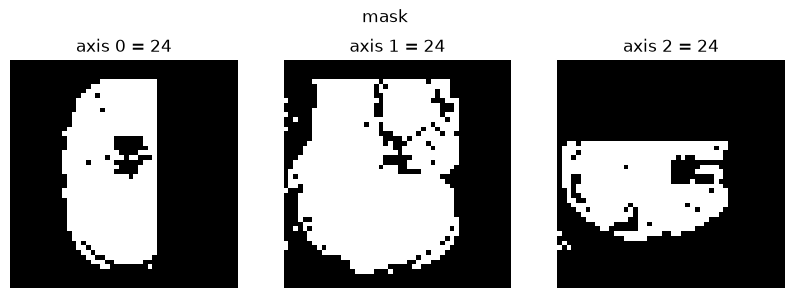

In [3]:
Gn, Gu, Gut = ml.bmTraj2SparseMat(t, ve, N_u, dK_u)
mask = ml.bmCoilSense_nonCart_mask_automatic(y_body, Gn, True)
y_ref, C_ref = ml.bmCoilSense_nonCart_ref(y_body, Gn, mask, None)
C_prime = ml.bmCoilSense_nonCart_primary(y_surface, y_ref, C_ref, Gn, ve, mask)
C = ml.bmCoilSense_nonCart_secondary(y_surface, C_prime, y_ref, C_ref, Gn, Gu, Gut, ve, 5, False)
savemat73(OUT / "coil_sensitivity_map.mat", {"C": C})
print(f"coil maps {C.shape} {C.dtype}, {time.time() - t0:.0f} s")
show_slices(mask, "mask")

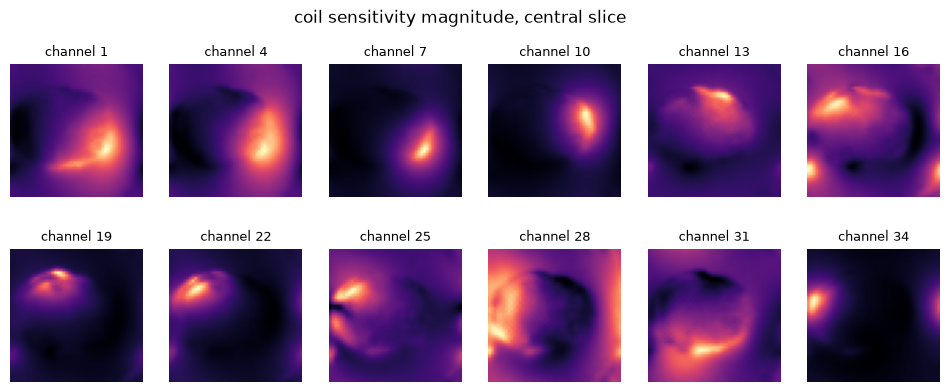

In [4]:
fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))
for k, a in enumerate(ax.flat):
    ch = k * (C.shape[3] // ax.size)
    a.imshow(np.abs(C[:, :, 24, ch]).T, cmap="magma", origin="lower")
    a.set_title(f"channel {ch + 1}", fontsize=9)
    a.axis("off")
fig.suptitle("coil sensitivity magnitude, central slice")
plt.show()

## 2. Binning

A binning mask is a logical array `(nBins, nLines)`: `True` where an acquired line goes into the
bin. Two binnings are made, as in the MATLAB tutorial:

- **all lines**: one bin with every line of the steady state, except the self-navigation line at
  the start of each shot (SI);
- **sequential**: consecutive 5 s windows (Siemens time stamps are in units of 2.5 ms).

45210 lines, 22 per shot; all lines: 42630 lines; sequential: 71 bins of about 596 lines


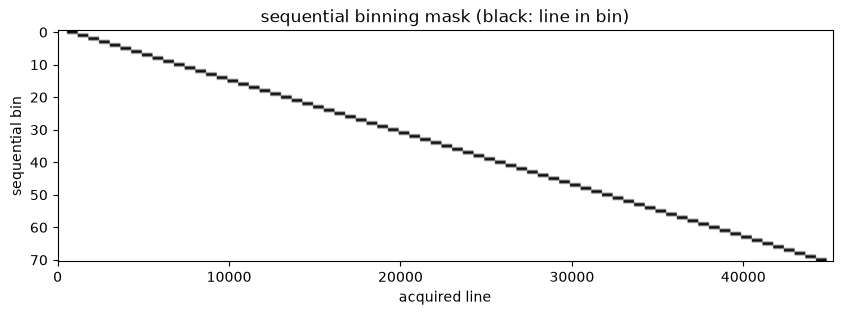

In [5]:
reader = ml.createRawDataReader(DATA / "brainScan.dat", True)
p = reader.acquisitionParams
nSeg, nLines = int(p.nSeg), int(p.nLine)
nExclude = int(p.nShot_off) * nSeg
ts = np.ravel(np.asarray(p.timestamp, dtype=np.float64))
timestampMs = (ts - ts.min()) * 2.5
si = np.arange(0, nLines, nSeg)  # first line of every shot (self navigation)

allLines = np.ones((1, nLines), dtype=bool)
allLines[0, :nExclude] = False
allLines[0, si] = False

window = 5 * 1000.0
start = timestampMs[nExclude]
nMasks = int(np.floor((timestampMs[-1] - start) / window))
seq = np.zeros((nMasks, nLines), dtype=bool)
for i in range(nMasks):
    w0 = start + i * window
    m = (timestampMs >= w0) & (timestampMs < w0 + window)
    m[si] = False
    seq[i] = m

savemat73(OUT / "binning.mat", {"allLinesMask": allLines, "sequentialMask": seq})
print(f"{nLines} lines, {nSeg} per shot; all lines: {allLines.sum()} lines; "
      f"sequential: {nMasks} bins of about {seq.sum(1).mean():.0f} lines")
fig, ax = plt.subplots(figsize=(10, 3))
ax.imshow(seq, aspect="auto", interpolation="antialiased", cmap="Greys")
ax.set_xlabel("acquired line")
ax.set_ylabel("sequential bin")
ax.set_title("sequential binning mask (black: line in bin)")
plt.show()

## 3. Mitosius: normalization and splitting of the raw data

All the raw data are read and gridded once (`x_tot`) to compute a normalization value: the mean
intensity in a region of the central slice. MATLAB asks you to draw that region; here it is a
centered disk of radius N/4. The normalized data are then split according to each binning
(`bmMitosis`), the volume elements are computed per bin, and everything is written to a
*mitosius* folder (one per binning) that the reconstructions read.

In [6]:
p.traj_type = "full_radial3_phylotaxis"
y_tot = reader.readRawData(True, True)
t_tot = ml.bmTraj(p)
ve_tot = ml.bmVolumeElement(t_tot, "voronoi_full_radial3")
FoV = float(np.ravel(p.FoV)[0])
N = int(FoV / 3)  # 3 mm voxels
N_u = np.array([[N, N, N]], dtype=np.float64)
dK_u = np.array([[1.0, 1.0, 1.0]]) / FoV
C_N = ml.bmImResize(C, [48, 48, 48], N_u)  # coil maps at the image resolution
# the MATLAB tutorial grids this normalization image with dK_u = 1/384 (not 1/FoV); kept identical
x_tot = ml.bmMathilda(y_tot, t_tot, ve_tot, C_N, N_u, N_u, np.array([[1.0, 1.0, 1.0]]) / 384)
print(f"raw data {y_tot.shape}, image {x_tot.shape}")

Running 'voronoin' and 'convhulln'... can take some time ...


... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...


... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...


... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...


... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...


... 'voronoin' and 'convhulln' done !
Running 'voronoin' and 'convhulln'... can take some time ...


... 'voronoin' and 'convhulln' done !


 
This is Mathilda...  
Matrix size  80  80  80 . 
FoV          384  384  384 . 
 


raw data (42, 480, 42630), image (80, 80, 80)


normalization value 2.6278038e-09


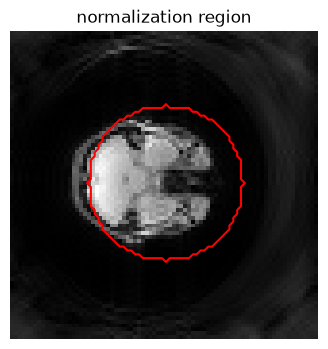

In [7]:
temp_im = np.abs(x_tot[:, :, N // 2])
gx, gy = np.meshgrid(np.arange(1, N + 1), np.arange(1, N + 1), indexing="ij")
roi = (gx - (N / 2 + 1)) ** 2 + (gy - (N / 2 + 1)) ** 2 <= (N / 4) ** 2
normalize_val = np.mean(temp_im[roi])
y_tot = y_tot / normalize_val
savemat73(OUT / "mitosius_prep.mat", {"x_tot": x_tot, "normalize_val": np.float32(normalize_val),
                                      "ve_tot": ve_tot})
print("normalization value", normalize_val)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(temp_im.T, cmap="gray", origin="lower")
ax.contour(roi.T, levels=[0.5], colors="r")
ax.set_title("normalization region")
ax.axis("off")
plt.show()

In [8]:
nShot_off = int(p.nShot_off)
for name, mask in {"allLines": allLines, "sequential": seq}.items():
    m = np.reshape(mask, (mask.shape[0], nSeg, mask.shape[1] // nSeg), order="F")
    m = m[:, 1:, nShot_off:]  # drop the SI line and the discarded shots, as the raw data
    m = ml.bmPointReshape(m)
    with quiet():
        y, t = ml.bmMitosis(y_tot, t_tot, m, nargout=2)
        y = ml.bmPermuteToCol(y)
        ve = ml.bmVolumeElement(t, "voronoi_full_radial3")
        ml.bmMitosius_create(str(OUT / f"mitosius_{name}"), y, t, ve)
    print(f"mitosius_{name}: {y.size} bin(s)")
del y_tot, t_tot, ve_tot  # free memory

mitosius_allLines: 1 bin(s)


mitosius_sequential: 71 bin(s)


## 4. Gridded reconstructions

Each bin is reconstructed with `bmMathilda` (density-compensated gridding and coil combination):
one image with all the lines, and the first 8 sequential 5 s bins.

 
This is Mathilda...  
Matrix size  80  80  80 . 
FoV          240  240  240 . 
 


done in 309 s


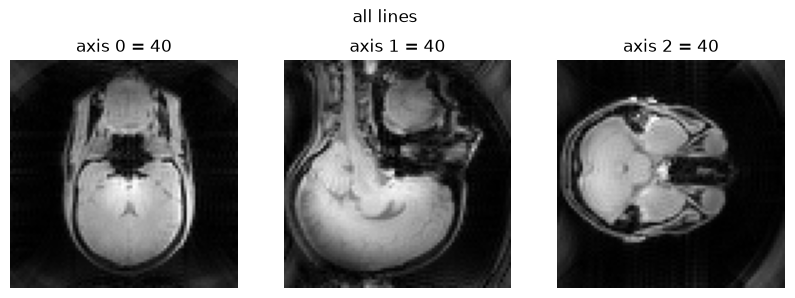

In [9]:
d = str(OUT / "mitosius_allLines")
y, t, ve = (ml.bmMitosius_load(d, k) for k in ("y", "t", "ve"))
x0 = ml.bmMathilda(y.flat[0], t.flat[0], ve.flat[0], C_N, N_u, N_u, dK_u)

nFr = 8
d = str(OUT / "mitosius_sequential")
y, t, ve = (ml.bmMitosius_load(d, k) for k in ("y", "t", "ve"))
with quiet():
    x1 = [ml.bmMathilda(y.flat[i], t.flat[i], ve.flat[i], C_N, N_u, N_u, dK_u) for i in range(nFr)]
savemat73(OUT / "reconstructions.mat", {"x0": x0, **{f"x1_{i + 1}": x for i, x in enumerate(x1)}})
print(f"done in {time.time() - t0:.0f} s")
show_slices(x0, "all lines")

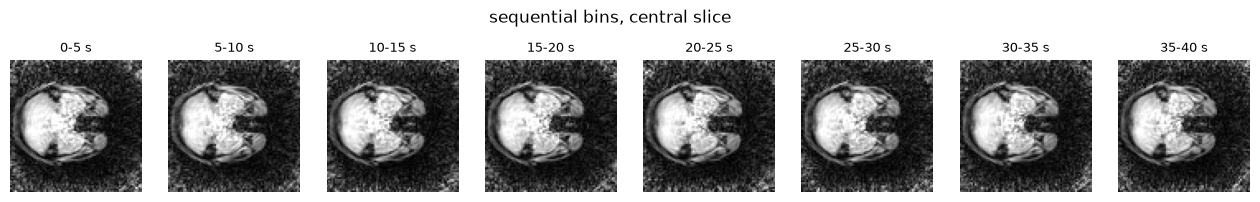

In [10]:
vmax = np.percentile(np.abs(x0), 99.5)
fig, ax = plt.subplots(1, nFr, figsize=(2 * nFr, 2.4))
for i, a in enumerate(ax):
    a.imshow(np.abs(x1[i][:, :, N // 2]).T, cmap="gray", origin="lower", vmax=vmax)
    a.set_title(f"{5 * i}-{5 * (i + 1)} s", fontsize=9)
    a.axis("off")
fig.suptitle("sequential bins, central slice")
plt.show()

## Reading the results later

The results are MATLAB v7.3 files (HDF5), so MATLAB `load` reads them too. In Python:

```python
from monalisa.readWrite._mat73 import loadmat73
r = loadmat73("results/reconstructions.mat")   # dict: x0, x1_1, ..., x1_8
```